# 05. 学習結果（Diffusion Policy・ACT）

04で作成したデータセットを使い、2種類の模倣学習の方策を学習した。

| 方策 | 学習データ（04） | 学習結果 |
|---|---|---|
| Diffusion Policy（DP） | 手首カメラ選別版（437エピソード） | `training_results/dp/` |
| ACT | 基本版（457エピソード） | `training_results/act/` |

**学習の実施場所について**

学習はGPUを持つ別のPC（以下、学習用PC）で行った。
その結果をコピーして転記するため、一部実行順が合わない点に留意。

In [ ]:
# ============================================================
# パス設定
# ============================================================
# このノートブックはfor_submit/ディレクトリで実行することを前提とする。
import json
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd()                                  # for_submit/ディレクトリ
OUT_DIR = ROOT / "outputs"
DP_DIR = ROOT / "training_results" / "dp"          # DPの学習結果
ACT_DIR = ROOT / "training_results" / "act"        # ACTの学習結果
# 04で作ったデータセット（予測の確認に使う）
DATASET_DP = OUT_DIR / "so101_lerobot_dataset_wristcam"
DATASET_ACT = OUT_DIR / "so101_lerobot_dataset"
# 学習再開用の状態ファイル（大きいのでtraining_results/にはコピーしていない）
ORIGINAL_ASSETS = ROOT.parent / "assets"
STATE_DP = (ORIGINAL_ASSETS / "so101_diffusion_policyv2"
            / "so101_diffusion_policy" / "training_state.pt")
STATE_ACT = ORIGINAL_ASSETS / "so101_act_policy" / "training_state.pt"

JOINT_NAMES = ["shoulder_pan", "shoulder_lift", "elbow_flex",
               "wrist_flex", "wrist_roll", "gripper"]
for path in [DP_DIR, ACT_DIR, DATASET_DP, DATASET_ACT]:
    print(f"{'あり' if path.exists() else 'なし'}  {path.relative_to(ROOT)}")

あり  training_results/dp
あり  training_results/act
あり  outputs/so101_lerobot_dataset_wristcam
あり  outputs/so101_lerobot_dataset


In [ ]:
# グラフスタイル設定

# 系列の色は固定順で割り当てる（1:青, 2:橙, 3:緑青, 4:黄, 5:桃, 6:緑, 7:紫, 8:赤）。
# 成功/失敗などの「状態」には、系列色とは別に専用の2色を使う。
import matplotlib.pyplot as plt
import japanize_matplotlib

SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                 "#e87ba4", "#008300", "#6250d6", "#e34948"]
COLOR_GOOD = "#0ca30c"      # 成功・採用を表す色
COLOR_BAD = "#d03b3b"       # 失敗・除外を表す色
COLOR_MUTED = "#898781"     # 補助線・参考情報の色

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "lines.linewidth": 2.0,
    "legend.frameon": False,
})

## 1.1 学習環境

In [ ]:
# パッケージ確認
def check_pkg(name):
    try:
        __import__(name)
        import importlib.metadata
        ver = importlib.metadata.version(name)
        return True, ver
    except Exception:
        return False, None

packages = {
    'torch':    'torch torchvision --index-url https://download.pytorch.org/whl/cu118',
    'lerobot':  'lerobot',
}

all_ok = True
for pkg, install_cmd in packages.items():
    ok, ver = check_pkg(pkg)
    if ok:
        print(f"✓ {pkg} {ver}")
    else:
        print(f"✗ {pkg} — 未インストール")
        print(f"    pip install {install_cmd}")
        all_ok = False

if all_ok:
    import torch
    print(f"\nCUDA available: {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("\n⚠ 上記パッケージをインストールしてカーネルを再起動してください")

✓ torch 2.11.0+rocm7.2
✓ lerobot 0.6.1

CUDA available: True
GPU: AMD Radeon Graphics


## 1.2 LeRobotデータセットの検証

In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import json
import numpy as np
import pandas as pd
from pathlib import Path

DATASET_DIR    = "assets/so101_lerobot_dataset"
OUTPUT_DIR     = "assets/so101_diffusion_policy"

dataset_dir = Path(DATASET_DIR)
assert dataset_dir.exists(), f"データセットが見つかりません: {dataset_dir}\nphase6_retarget_summary.ipynbを先に実行してください"

with open(dataset_dir / "meta" / "info.json") as f:
    info = json.load(f)

tasks_df = pd.read_parquet(dataset_dir / "meta" / "tasks.parquet")
first_task = tasks_df.index[0]

print("=== LeRobotデータセット情報 ===")
print(f"エピソード数  : {info['total_episodes']}")
print(f"総フレーム数  : {info['total_frames']}")
print(f"FPS           : {info['fps']}")
print(f"タスク        : {first_task}")
ml_keys = [k for k in info['features'] if k not in ('episode_index','frame_index','index','task_index','timestamp')]
print(f"features keys : {ml_keys}")
print(f"joint names   : {info['features']['action']['names']}")

# 動画が含まれているか確認
HAS_VIDEO = "observation.image" in info["features"]
if HAS_VIDEO:
    img_shape = info["features"]["observation.image"]["shape"]   # [H, W, C]
    print(f"observation.image: {img_shape[0]}×{img_shape[1]}×{img_shape[2]}")
    print("  → VISUAL入力付きDiffusion Policyで学習")
else:
    img_shape = None
    print("observation.image: なし（state-onlyモード）")

data_path = dataset_dir / "data" / "chunk-000" / "file-000.parquet"
df_all = pd.read_parquet(data_path)

lengths = df_all.groupby("episode_index").size().tolist()
print(f"\n=== エピソード長分布 ===")
print(f"min={min(lengths)}, max={max(lengths)}, mean={np.mean(lengths):.0f}")

=== LeRobot データセット情報 ===
エピソード数  : 437
総フレーム数  : 66468
FPS           : 30
タスク        : Pick up the cube
features keys : ['action', 'observation.state', 'observation.image']
joint names   : ['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']
observation.image: 3×160×160
  → VISUAL 入力付き Diffusion Policy で学習

=== エピソード長分布 ===
min=78, max=386, mean=152


In [ ]:
# actionの統計（絶対値であることを確認）
from grabette_phase5.lerobot_exporter import JOINT_NAMES, JOINT_LOWER, JOINT_UPPER

actions = np.array(df_all['action'].tolist(), dtype=np.float32)  # (N_total, 6)

print("=== action（絶対関節角度[rad]）統計 ===")
print(f"{'関節':<16} {'mean':>8} {'std':>8} {'min':>8} {'max':>8} {'range[deg]':>12}")
print("-" * 60)
for i, name in enumerate(JOINT_NAMES):
    m, s, lo, hi = actions[:,i].mean(), actions[:,i].std(), actions[:,i].min(), actions[:,i].max()
    rng_deg = np.degrees(hi - lo)
    print(f"{name:<16} {m:>8.3f} {s:>8.3f} {lo:>8.3f} {hi:>8.3f} {rng_deg:>12.1f}")

print()
# wrist_rollはほぼ -π/2で固定されているはず
wr_std = actions[:,4].std()
print(f"wrist_roll std: {wr_std:.4f} rad → {'固定値（正常）' if wr_std < 0.01 else '変動あり（要確認）'}")

=== action（絶対関節角度 [rad]）統計 ===
関節                   mean      std      min      max   range[deg]
------------------------------------------------------------
shoulder_pan       -0.073    0.218   -1.858    1.920        216.5
shoulder_lift      -0.705    0.816   -1.745    1.064        161.0
elbow_flex          1.417    0.187   -0.336    1.690        116.1
wrist_flex         -0.251    1.266   -1.658    1.658        190.0
wrist_roll         -1.571    0.000   -1.571   -1.571          0.0
gripper             0.935    0.697    0.000    1.745        100.0

wrist_roll std: 0.0000 rad → 固定値（正常）


In [ ]:
# ACTION / STATE MIN_MAX正規化

# meta/stats.jsonから読み込む（phase6でエクスポートされたデータセット統計）
# wrist_rollはmin==maxなので0.0に固定正規化（clip_sample_range=1.0と整合）

import json
import torch
from pathlib import Path

_stats_path = Path(DATASET_DIR) / "meta" / "stats.json"
with open(_stats_path) as f:
    _stats = json.load(f)

ACTION_MIN = torch.tensor(_stats["action"]["min"], dtype=torch.float32)
ACTION_MAX = torch.tensor(_stats["action"]["max"], dtype=torch.float32)
ACTION_RANGE = ACTION_MAX - ACTION_MIN
_state_stats = _stats.get("observation.state", _stats["action"])
STATE_MIN = torch.tensor(_state_stats["min"], dtype=torch.float32)
STATE_MAX = torch.tensor(_state_stats["max"], dtype=torch.float32)


def normalize_minmax(x: torch.Tensor, x_min: torch.Tensor, x_max: torch.Tensor) -> torch.Tensor:
    """Normalize to [-1, 1]. Constant dims (wrist_roll, min==max) → 0.0."""
    r = x_max - x_min
    safe_r = torch.where(r < 1e-8, torch.ones_like(r), r)
    norm = 2.0 * (x - x_min) / safe_r - 1.0
    return torch.where(r < 1e-8, torch.zeros_like(norm), norm)


def denormalize_minmax(norm: torch.Tensor, x_min: torch.Tensor, x_max: torch.Tensor) -> torch.Tensor:
    """Denormalize from [-1, 1] to original range."""
    return (norm + 1.0) / 2.0 * (x_max - x_min) + x_min

def save_normalization_stats(directory: Path) -> Path:
    """学習と推論で同じACTION/STATEの統計を使えるよう保存する。"""
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / "action_stats.json"
    stats_out = {
        "version": 1,
        "method": "minmax_-1_1",
        "action_min": ACTION_MIN.tolist(),
        "action_max": ACTION_MAX.tolist(),
        "state_min": STATE_MIN.tolist(),
        "state_max": STATE_MAX.tolist(),
    }
    with open(path, "w", encoding="utf-8") as f:
        json.dump(stats_out, f, indent=2)
    return path


print("=== MIN_MAX正規化統計 ===")
for i, name in enumerate(info['features']['action']['names']):
    print(f"  {name:<16}: min={ACTION_MIN[i]:+.4f}  max={ACTION_MAX[i]:+.4f}  range={ACTION_RANGE[i]:.4f}")

norm_min = normalize_minmax(ACTION_MIN, ACTION_MIN, ACTION_MAX)
norm_max = normalize_minmax(ACTION_MAX, ACTION_MIN, ACTION_MAX)
print(f"\n正規化後min: {norm_min.numpy().round(3)}")
print(f"正規化後max: {norm_max.numpy().round(3)}")
print("→ 全次元が[-1, 1]に収まること（clip_sample_range=1.0と整合）を確認")
print("→ wrist_rollはrange=0のため0.0固定（逆正規化で-1.5708に復元される）")

=== MIN_MAX 正規化統計 ===
  shoulder_pan    : min=-1.8580  max=+1.9198  range=3.7778
  shoulder_lift   : min=-1.7453  max=+1.0640  range=2.8093
  elbow_flex      : min=-0.3360  max=+1.6900  range=2.0260
  wrist_flex      : min=-1.6581  max=+1.6581  range=3.3161
  wrist_roll      : min=-1.5708  max=-1.5708  range=0.0000
  gripper         : min=+0.0000  max=+1.7453  range=1.7453

正規化後 min: [-1. -1. -1. -1.  0. -1.]
正規化後 max: [1. 1. 1. 1. 0. 1.]
→ 全次元が [-1, 1] に収まること（clip_sample_range=1.0 と整合）を確認
→ wrist_roll は range=0 のため 0.0 固定（逆正規化で -1.5708 に復元される）


## 1.3 Diffusion Policy設定

In [ ]:
# Diffusion Policy設定
# lerobotのDiffusionConfigを使って学習設定を構築する。
N_OBS_STEPS = 2
HORIZON = 16
N_ACTION_STEPS = 8
BATCH_SIZE = 256
LEARNING_RATE = 1e-4
NUM_EPOCHS = 150
NUM_DIFF_ITERS = 100

FPS = info['fps']

obs_delta = [i / FPS for i in range(-N_OBS_STEPS + 1, 1)] # [-1/30, 0]
act_delta = [i / FPS for i in range(1, HORIZON + 1)] # [1/30, ..., 16/30]

NUM_WORKERS = 4

print("=== 学習設定 ===")
print(f"n_obs_steps    : {N_OBS_STEPS}")
print(f"horizon       : {HORIZON}")
print(f"n_action_steps : {N_ACTION_STEPS}")
print(f"batch_size     : {BATCH_SIZE}")
print(f"learning_rate  : {LEARNING_RATE}")
print(f"num_epochs    : {NUM_EPOCHS}")
print(f"num_diff_iters : {NUM_DIFF_ITERS}")
print(f"obs_delta_t   : {[f'{t:.3f}' for t in obs_delta]} s")
print(f"action_delta_t : {[f'{t:.3f}' for t in act_delta[:4]]} ... ({HORIZON} steps)")
if HAS_VIDEO:
    C, H, W = img_shape # img_shape [C, H, W]
    print(f"\n観測モード      : VISUAL + STATE ({H}{W}px + 6D関節角度)")
    print(f"VRAM目安       : ~6-10 GB (batch={BATCH_SIZE})")
    print(f"※ BATCH_SIZEを8-16に下げるとVRAM 2-3 GB程度に削減可能")
else:
    print(f"\n観測モード      : STATE-ONLY (6D関節角度のみ)")
    print(f"VRAM目安       : ~500 MB-1 GB (batch={BATCH_SIZE})")

=== 学習設定 ===
n_obs_steps    : 2
horizon       : 16
n_action_steps : 8
batch_size     : 256
learning_rate  : 0.0001
num_epochs    : 150
num_diff_iters : 100
obs_delta_t   : ['-0.033', '0.000'] s
action_delta_t : ['0.033', '0.067', '0.100', '0.133'] ... (16 steps)

観測モード      : VISUAL + STATE (160160px + 6D 関節角度)
VRAM 目安       : ~6-10 GB (batch=256)
※ BATCH_SIZE を 8-16 に下げると VRAM 2-3 GB 程度に削減可能


In [ ]:
# ボリシーの構架確認(lerobotインストール済みの場合)
# try:
import torch
from pathlib import Path
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from lerobot.policies.diffusion.configuration_diffusion import DiffusionConfig
from lerobot.policies.diffusion.modeling_diffusion import DiffusionPolicy
from lerobot.configs.types import FeatureType, PolicyFeature

# delta_timestamps: 観測モードに応じてキーを追加
delta_ts: dict = {
    "observation.state": obs_delta,
    "action": act_delta,
}

if HAS_VIDEO:
    delta_ts["observation.image"] = obs_delta # 同じ時間で画像を観测

dataset = LeRobotDataset(
    root=Path(DATASET_DIR),
    repo_id="local/so101",
    delta_timestamps=delta_ts,
)
print(f"Dataset: {len(dataset)} samples, {dataset.num_episodes} episodes")

# input_features: VISUALがある場合はobservation.imageを追加
input_features: dict = {
    "observation.state": PolicyFeature(type=FeatureType.STATE, shape=(6,)),
}
if HAS_VIDEO:
    C, H, W = img_shape # img_shapeは[C, H, W]のinfo.jsonのshapeフィールドと同じ
    input_features["observation.image"] = PolicyFeature(
        type=FeatureType.VISUAL, shape=(C, H, W),
    )
    print(f"VISUAL feature追加: (C={C}, H={H}, W={W})")

config = DiffusionConfig(
    input_features=input_features,
    output_features={
        "action": PolicyFeature(type=FeatureType.ACTION, shape=(6,)),
    },
    n_obs_steps=N_OBS_STEPS,
    horizon=HORIZON,
    n_action_steps=N_ACTION_STEPS,
    num_train_timesteps=NUM_DIFF_ITERS,
    num_inference_steps=NUM_DIFF_ITERS,
    down_dims=(256, 512, 1024),
    kernel_size=5,
    n_groups=8,
    diffusion_step_embed_dim=128,
)

# STATE-onlyの場合のみvalidate_featuresを無効化
# VISUALがある場合はlerobotの画像チェックが通るため不要)
if not HAS_VIDEO:
    config.validate_features = lambda: None

policy = DiffusionPolicy(config)
n_params = sum(p.numel() for p in policy.parameters())
print(f"Policy parameters: {n_params:,}")
print("Policy created successfully")

# except ImportError as e:
#     print(f"lerobot/torch未インストール: {e}")
#     print("セル1の指示に使ってインストール後、カーネルを再起動してください")

/home/hk/.cache/pypoetry/virtualenvs/so101-DPkbPfKI-py3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: 66468 samples, 437 episodes
VISUAL feature 追加: (C=3, H=160, W=160)
Policy parameters: 76,192,294
Policy created successfully


## 1.4 学習実行

In [ ]:
import json as _json
import time
import torch
from torch.utils.data import DataLoader
from torch.cuda.amp import autocast, GradScaler
from pathlib import Path
import gc

device = "cuda" if torch.cuda.is_available() else "cpu"
policy = policy.to(device)

# 【重要】DataLoader最適化設定
# # CPUコア数を確認
NUM_WORKERS = 5

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,  # 64
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device == "cuda"),
    persistent_workers=False,
    prefetch_factor=3,
    drop_last=True,
)

optimizer = torch.optim.Adam(policy.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS * max(len(dataloader), 1)
)

# Mixed Precision有効化
USE_MIXED_PRECISION = True
scaler = GradScaler() if USE_MIXED_PRECISION else None

output_path = Path(OUTPUT_DIR)
output_path.mkdir(parents=True, exist_ok=True)
stats_path = save_normalization_stats(output_path)
print(f"✅ ACTION/STATE正規化統計を保存: {stats_path}")
a_min_d, a_max_d = ACTION_MIN.to(device), ACTION_MAX.to(device)
s_min_d, s_max_d = STATE_MIN.to(device), STATE_MAX.to(device)
log_path = output_path / "training_log.jsonl"

best_loss = float("inf")

print("=" * 60)
print("🚀 Diffusion Policy最適化学習スタート")
print("=" * 60)
print(f"✅ DataLoader最適化:")
print(f"   - num_workers: {NUM_WORKERS} (0 → 6)")
print(f"   - prefetch_factor: 2")
print(f"✅ Mixed Precision: {'有効' if USE_MIXED_PRECISION else '無効'}")
print(f"✅ Batch Size: {BATCH_SIZE}")
print(f"✅ Device: {device}")
print("=" * 60)

# 実行
 
best_loss = float("inf")
 
with open(log_path, "w", encoding="utf-8") as log_f:
    for epoch in range(1, NUM_EPOCHS + 1):
        policy.train()
        total_loss = 0.0
        n_batches = 0
        epoch_start = time.time()
        
        for batch in dataloader:
            batch = {k: v.to(device) if isinstance(v, torch.Tensor) else v
                  for k, v in batch.items()}
            # 学習入力と教師actionを同じ定義[-1, 1]に揃える
            batch["action"] = normalize_minmax(batch["action"], a_min_d, a_max_d)
            batch["observation.state"] = normalize_minmax(
                batch["observation.state"], s_min_d, s_max_d)
            
            # STATE-ONLYの場合
            if not HAS_VIDEO:
                batch["observation.environment_state"] = batch["observation.state"]
            
            optimizer.zero_grad()
            
            with autocast():
                loss, _ = policy.forward(batch)
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            
            scheduler.step()
            total_loss += loss.item()
            n_batches += 1
        
        epoch_time = time.time() - epoch_start
        avg = total_loss / max(n_batches, 1)
        lr_now = scheduler.get_last_lr()[0]
        
        # ===== ログ保存 =====
        log_f.write(_json.dumps({
            "epoch": epoch,
            "loss": round(avg, 8),
            "lr": round(lr_now, 8),
            "epoch_time": round(epoch_time, 2),
            "timestamp": time.time(),
        }) + "\n")
        log_f.flush()
        
        # ===== チェックポイント保存 =====
        if avg < best_loss:
            best_loss = avg
            policy.save_pretrained(str(output_path / "best"))
            save_normalization_stats(output_path / "best")
        
        if epoch % 10 == 0 or epoch == NUM_EPOCHS:
            print(f"Epoch {epoch:4d}/{NUM_EPOCHS} | loss={avg:.6f} | lr={lr_now:.2e} | time={epoch_time:.1f}s")
            policy.save_pretrained(str(output_path / f"checkpoint_{epoch:05d}"))
            save_normalization_stats(output_path / f"checkpoint_{epoch:05d}")
            
            # 【重要】トレーニング状態を保存
            state_to_save = {
                "epoch": epoch,
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_loss": best_loss,
            }
            torch.save(state_to_save, str(output_path / "training_state.pt"))

        # エポック終了後
        if epoch % 20 == 0:
            gc.collect()  # ガベージコレクション
            if device == "cuda":
                torch.cuda.empty_cache()
 
print(f"\n✨ 学習完了!")
print(f"Best loss: {best_loss:.6f}")

✅ ACTION/STATE 正規化統計を保存: assets/so101_diffusion_policy/action_stats.json
🚀 Diffusion Policy 最適化学習スタート
✅ DataLoader最適化:
   - num_workers: 5 (0 → 6)
   - prefetch_factor: 2
✅ Mixed Precision: 有効
✅ Batch Size: 256
✅ Device: cuda


/tmp/ipykernel_1304182/3046774300.py:48: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() if USE_MIXED_PRECISION else None
/tmp/ipykernel_1304182/3046774300.py:99: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch   10/150 | loss=0.010290 | lr=9.89e-05 | time=255.6s
Epoch   20/150 | loss=0.007506 | lr=9.57e-05 | time=256.5s
Epoch   30/150 | loss=0.006337 | lr=9.05e-05 | time=256.3s
Epoch   40/150 | loss=0.005187 | lr=8.35e-05 | time=255.4s
Epoch   50/150 | loss=0.004549 | lr=7.50e-05 | time=256.2s
Epoch   60/150 | loss=0.003969 | lr=6.55e-05 | time=255.9s
Epoch   70/150 | loss=0.003354 | lr=5.52e-05 | time=257.0s
Epoch   80/150 | loss=0.002904 | lr=4.48e-05 | time=254.9s
Epoch   90/150 | loss=0.002498 | lr=3.45e-05 | time=255.1s
Epoch  100/150 | loss=0.001924 | lr=2.50e-05 | time=256.2s
Epoch  110/150 | loss=0.001580 | lr=1.65e-05 | time=256.4s
Epoch  120/150 | loss=0.001275 | lr=9.55e-06 | time=257.4s
Epoch  130/150 | loss=0.001027 | lr=4.32e-06 | time=257.1s
Epoch  140/150 | loss=0.000882 | lr=1.09e-06 | time=257.3s
Epoch  150/150 | loss=0.000896 | lr=0.00e+00 | time=257.8s

✨ 学習完了!
Best loss: 0.000848


### 2.1 学習ログの確認

学習中に毎エポック書き出されたログtraining_results/dp/training_log.jsonlを確認

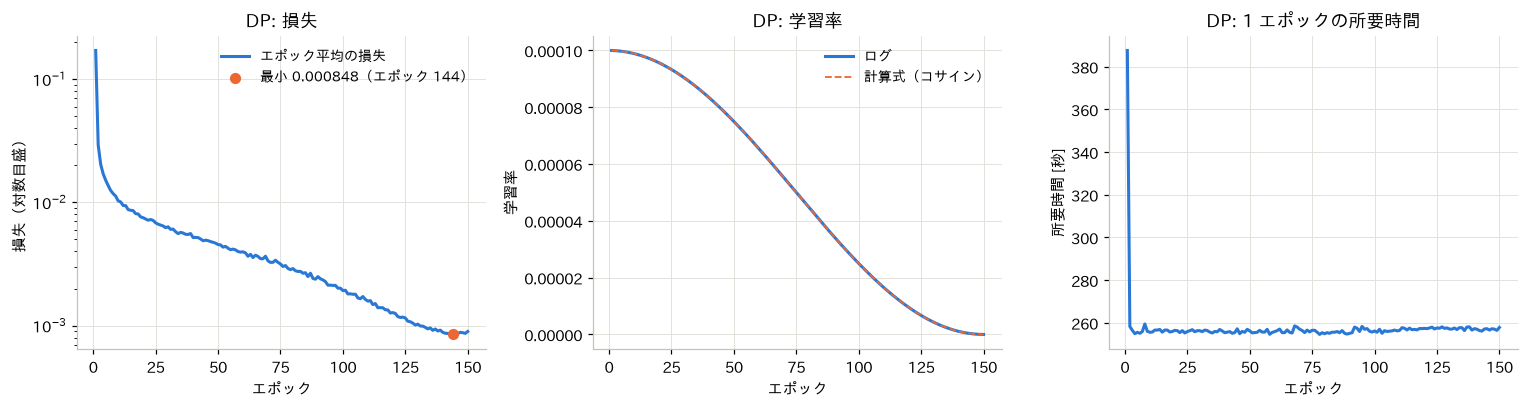

In [6]:
# 3. ロス曲線
def plot_training_curves(log, name, filename):
    """損失（対数目盛）・学習率・1エポックの所要時間を並べて描く。"""
    best = log.loc[log["loss"].idxmin()]
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    axes[0].semilogy(log["epoch"], log["loss"], color=SERIES_COLORS[0],
                     label="エポック平均の損失")
    axes[0].scatter(best["epoch"], best["loss"], color=SERIES_COLORS[1],
                    zorder=3, s=40,
                    label=f"最小{best['loss']:.6f}（エポック{int(best['epoch'])}）")
    axes[0].set_xlabel("エポック")
    axes[0].set_ylabel("損失（対数目盛）")
    axes[0].set_title(f"{name}: 損失")
    axes[0].legend(fontsize=9)
    axes[1].plot(log["epoch"], log["lr"], color=SERIES_COLORS[0],
                 label="ログ")
    axes[1].plot(log["epoch"], expected_lr(log["epoch"]),
                 color=SERIES_COLORS[1], ls="--", lw=1.2,
                 label="計算式（コサイン）")
    axes[1].set_xlabel("エポック")
    axes[1].set_ylabel("学習率")
    axes[1].set_title(f"{name}: 学習率")
    axes[1].legend(fontsize=9)
    axes[2].plot(log["epoch"], log["epoch_time"], color=SERIES_COLORS[0])
    axes[2].set_xlabel("エポック")
    axes[2].set_ylabel("所要時間 [秒]")
    axes[2].set_title(f"{name}: 1エポックの所要時間")
    plt.tight_layout()
    plt.savefig(OUT_DIR / filename, bbox_inches="tight")
    plt.show()


plot_training_curves(dp_log, "DP", "05_dp_training_curves.png")

### 2.2 学習済みモデルによる予測の確認

保存された最良モデルを読み込み、04で作ったDP用データセットから取り出したサンプルで、16フレーム先までの関節角を予測させる。
学習時と同じく、関節角は保存された正規化統計（best/action_stats.json）で−1〜1に変換してから入力する。

In [10]:
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from lerobot.policies.diffusion.modeling_diffusion import DiffusionPolicy

FPS = 30
dp_policy = DiffusionPolicy.from_pretrained(str(DP_DIR / "best"))
dp_policy.to("cpu").eval()
print(f"パラメータ数: {sum(p.numel() for p in dp_policy.parameters()):,}")
print("入力:", {k: v.shape for k, v in dp_policy.config.input_features.items()})

with open(DP_DIR / "best" / "action_stats.json") as f:
    dp_stats = {k: torch.tensor(v) for k, v in json.load(f).items()
                if isinstance(v, list)}


def to_minus1_1(x, low, high):
    """最小値〜最大値を−1〜1に変換する。範囲が0の関節（wrist_roll）は0にする。"""
    span = high - low
    safe = torch.where(span < 1e-8, torch.ones_like(span), span)
    scaled = 2.0 * (x - low) / safe - 1.0
    return torch.where(span < 1e-8, torch.zeros_like(scaled), scaled)


def from_minus1_1(x, low, high):
    """−1〜1の値を、最小値〜最大値の範囲に戻す。"""
    return (x + 1.0) / 2.0 * (high - low) + low


dp_dataset = LeRobotDataset(
    repo_id="local/so101", root=DATASET_DP, video_backend="pyav",
    delta_timestamps={
        "observation.state": [-1 / FPS, 0.0],
        "observation.image": [-1 / FPS, 0.0],
        "action": [k / FPS for k in range(1, 17)],
    })
print(f"データセット: {dp_dataset.num_episodes}エピソード, {len(dp_dataset):,}サンプル")

Loading weights from local directory
パラメータ数: 76,192,294
入力: {'observation.state': (6,), 'observation.image': (3, 160, 160)}
データセット: 437 エピソード, 66,467 サンプル


In [11]:
# データセットから32サンプルを無作為に選び、まとめて予測する
rng = np.random.default_rng(0)
sample_ids = rng.choice(len(dp_dataset), size=32, replace=False)
samples = [dp_dataset[int(i)] for i in sample_ids]
# 形: 状態(B, 2, 6)、画像(B, 2, 3, H, W)、正解(B, 16, 6)。Bはサンプル数
states = torch.stack([s["observation.state"] for s in samples])
images = torch.stack([s["observation.image"] for s in samples])
targets = torch.stack([s["action"] for s in samples])

with torch.no_grad():
    batch = {
        "observation.state": to_minus1_1(states, dp_stats["state_min"],
                                         dp_stats["state_max"]),
        # カメラが1台なので、カメラの次元（大きさ1）を加える: (B, 2, 1, 3, H, W)
        "observation.images": images.unsqueeze(2),
    }
    condition = dp_policy.diffusion._prepare_global_conditioning(batch)
    generator = torch.Generator().manual_seed(0)
    predicted = dp_policy.diffusion.conditional_sample(
        len(samples), global_cond=condition, generator=generator)
# −1〜1の予測を関節角[rad]に戻す: (B, 16, 6)
dp_predicted = from_minus1_1(predicted, dp_stats["action_min"],
                             dp_stats["action_max"])
dp_targets = targets
print("予測の形:", tuple(dp_predicted.shape))

予測の形: (32, 16, 6)


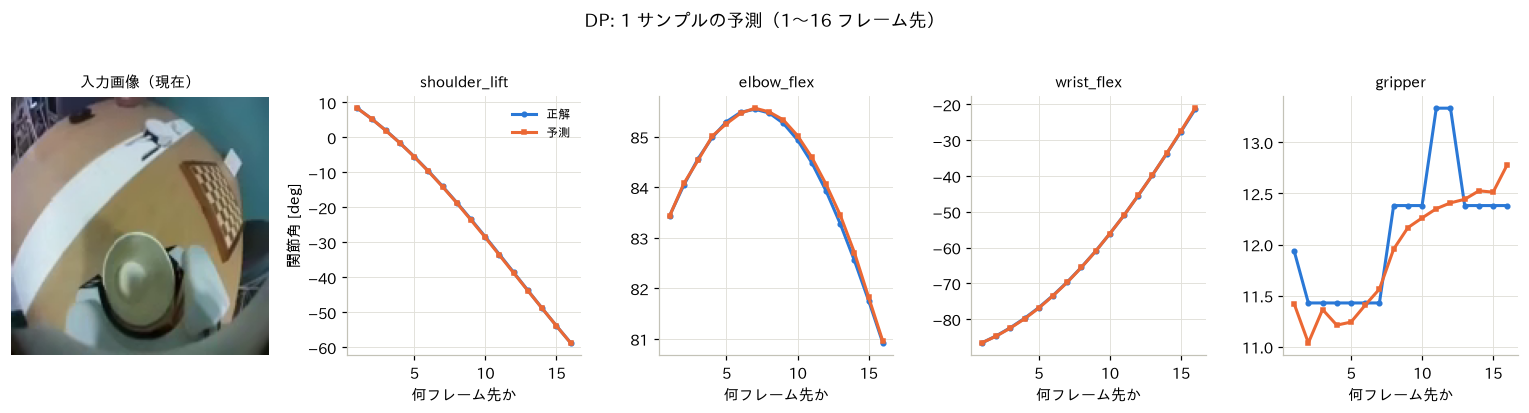

In [12]:
def plot_prediction(sample, predicted, target, image, title, steps, filename):
    """1サンプルの画像と、関節ごとの予測・正解の時系列を描く。"""
    fig = plt.figure(figsize=(14, 3.6))
    grid = fig.add_gridspec(1, 5, width_ratios=[1.1, 1, 1, 1, 1])
    ax = fig.add_subplot(grid[0])
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title("入力画像（現在）", fontsize=10)
    ax.axis("off")
    for k, j in enumerate([1, 2, 3, 5]):   # wrist_rollは一定値なので省く
        ax = fig.add_subplot(grid[k + 1])
        ax.plot(steps, np.degrees(target[:, j].numpy()),
                color=SERIES_COLORS[0], marker="o", markersize=3,
                label="正解")
        ax.plot(steps, np.degrees(predicted[:, j].numpy()),
                color=SERIES_COLORS[1], marker="s", markersize=3,
                label="予測")
        ax.set_title(JOINT_NAMES[j], fontsize=10)
        ax.set_xlabel("何フレーム先か")
        if k == 0:
            ax.set_ylabel("関節角[deg]")
            ax.legend(fontsize=8)
    plt.suptitle(title, y=1.03)
    plt.tight_layout()
    plt.savefig(OUT_DIR / filename, bbox_inches="tight")
    plt.show()


plot_prediction(samples[0], dp_predicted[0], dp_targets[0],
                samples[0]["observation.image"][-1],
                "DP: 1サンプルの予測（1〜16フレーム先）", range(1, 17),
                "05_dp_prediction_example.png")

In [13]:
def error_table(predicted, target):
    """関節ごとの予測誤差（絶対誤差の平均, 度）を、先の8フレームと16フレームで求める。"""
    error = np.degrees((predicted - target).abs().numpy())
    rows = {}
    for j, name in enumerate(JOINT_NAMES):
        rows[name] = {"先の8フレームの平均誤差[deg]": error[:, :8, j].mean(),
                      "先の16フレームの平均誤差[deg]": error[:, :, j].mean()}
    return pd.DataFrame(rows).T.round(2)


dp_errors = error_table(dp_predicted, dp_targets)
dp_errors

,先の 8 フレームの平均誤差 [deg],先の 16 フレームの平均誤差 [deg]
shoulder_pan,0.12,0.16
shoulder_lift,0.57,0.60
elbow_flex,0.13,0.16
wrist_flex,0.21,0.24
wrist_roll,0.00,0.00
gripper,0.34,0.32


リークデータに対するモデルによる予測は、どの関節も平均1度未満に収まった。学習自体は正常に進んでいると考えられる

## 3. ACT

### 3.1 学習の設定

| 項目 | 値 |
|---|---|
| 学習データ | 04の基本版（457エピソード） |
| 入力 | 現在のフレームの、手元カメラ画像（3 × 160 × 160）と関節角（6） |
| 出力 | 現在〜15フレーム先の関節角（6 × 16）。実行時は先頭8フレーム分を使う |
| 構造 | ResNet-18（ImageNetで事前学習済み）＋ Transformer（エンコーダ4層・デコーダ1層, 幅512）＋ VAE（潜在変数32次元） |
| 正規化 | 関節角（state・action）を、データセットの平均・標準偏差で標準化（lerobotの前処理器`preprocessor`を使用） |
| 最適化 | AdamW（重み減衰1e-4）。学習率は本体1e-4、画像の特徴抽出部（ResNet-18）1e-5から0へ（コサイン）、バッチサイズ128、150エポック |
| 損失 | 予測の絶対誤差 ＋ 10 × KL情報量 |
| パラメータ数 | 51,554,182 |

**転記: データセットの確認**（学習用ノートブックのセル4）

コード:

```python
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import json
import numpy as np
import pandas as pd
from pathlib import Path

DATASET_DIR    = "assets/so101_lerobot_dataset"
OUTPUT_DIR     = "assets/so101_act_policy"

dataset_dir = Path(DATASET_DIR)
assert dataset_dir.exists(), f"データセットが見つかりません: {dataset_dir}\nphase6_retarget_summary.ipynbを先に実行してください"

with open(dataset_dir / "meta" / "info.json") as f:
    info = json.load(f)

tasks_df = pd.read_parquet(dataset_dir / "meta" / "tasks.parquet")
first_task = tasks_df.index[0]

print("=== LeRobotデータセット情報 ===")
print(f"エピソード数  : {info['total_episodes']}")
print(f"総フレーム数  : {info['total_frames']}")
print(f"FPS           : {info['fps']}")
print(f"タスク        : {first_task}")
ml_keys = [k for k in info['features'] if k not in ('episode_index','frame_index','index','task_index','timestamp')]
print(f"features keys : {ml_keys}")
print(f"joint names   : {info['features']['action']['names']}")

# 動画が含まれているか確認
HAS_VIDEO = "observation.image" in info["features"]
if HAS_VIDEO:
    img_shape = info["features"]["observation.image"]["shape"]   # [H, W, C]
    print(f"observation.image: {img_shape[0]}×{img_shape[1]}×{img_shape[2]}")
    print("  → VISUAL + STATE入力のACT Behavior Cloningで学習")
else:
    img_shape = None
    print("observation.image: なし（state-onlyモード）")

data_path = dataset_dir / "data" / "chunk-000" / "file-000.parquet"
df_all = pd.read_parquet(data_path)

lengths = df_all.groupby("episode_index").size().tolist()
print(f"\n=== エピソード長分布 ===")
print(f"min={min(lengths)}, max={max(lengths)}, mean={np.mean(lengths):.0f}")
```

出力:

```text
=== LeRobotデータセット情報 ===
エピソード数  : 457
総フレーム数  : 69557
FPS           : 30
タスク        : Pick up the cube
features keys : ['action', 'observation.state', 'observation.image']
joint names   : ['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']
observation.image: 3×160×160
  → VISUAL + STATE入力のACT Behavior Cloningで学習
=== エピソード長分布 ===
min=78, max=386, mean=152
```

**転記: actionの統計**（学習用ノートブックのセル5）

コード:

```python
# actionの統計（絶対値であることを確認）
from grabette_phase5.lerobot_exporter import JOINT_NAMES, JOINT_LOWER, JOINT_UPPER

actions = np.array(df_all['action'].tolist(), dtype=np.float32)  # (N_total, 6)

print("=== action（絶対関節角度[rad]）統計 ===")
print(f"{'関節':<16} {'mean':>8} {'std':>8} {'min':>8} {'max':>8} {'range[deg]':>12}")
print("-" * 60)
for i, name in enumerate(JOINT_NAMES):
    m, s, lo, hi = actions[:,i].mean(), actions[:,i].std(), actions[:,i].min(), actions[:,i].max()
    rng_deg = np.degrees(hi - lo)
    print(f"{name:<16} {m:>8.3f} {s:>8.3f} {lo:>8.3f} {hi:>8.3f} {rng_deg:>12.1f}")

print()
# wrist_rollはほぼ -π/2で固定されているはず
wr_std = actions[:,4].std()
print(f"wrist_roll std: {wr_std:.4f} rad → {'固定値（正常）' if wr_std < 0.01 else '変動あり（要確認）'}")
```

出力:

```text
=== action（絶対関節角度[rad]）統計 ===
関節                   mean      std      min      max   range[deg]
------------------------------------------------------------
shoulder_pan       -0.067    0.225   -1.858    1.920        216.5
shoulder_lift      -0.676    0.822   -1.745    1.168        166.9
elbow_flex          1.414    0.188   -0.336    1.690        116.1
wrist_flex         -0.278    1.268   -1.658    1.658        190.0
wrist_roll         -1.571    0.000   -1.571   -1.571          0.0
gripper             0.933    0.694    0.000    1.745        100.0
wrist_roll std: 0.0000 rad → 固定値（正常）
```

**転記: 学習の設定**（学習用ノートブックのセル7）

コード:

```python
# ACT Behavior Cloning設定
# LeRobotのACTは現行実装でn_obs_steps=1を要求する。
N_OBS_STEPS = 1
CHUNK_SIZE = 16
N_ACTION_STEPS = 8
# ACTはDiffusion Policyより画像バックボーンとVAEのメモリ使用量が大きいため、まず32で開始する。
BATCH_SIZE = 128
LEARNING_RATE = 1e-4
NUM_EPOCHS = 150
KL_WEIGHT = 10.0

FPS = info['fps']

# 現在の画像・状態を入力し、現在から将来CHUNK_SIZEフレームを教師にする。
obs_delta = [0.0]
act_delta = [i / FPS for i in range(CHUNK_SIZE)] # [0, 1/30, ..., 15/30]

NUM_WORKERS = 4

print("=== 学習設定 ===")
print(f"n_obs_steps    : {N_OBS_STEPS}")
print(f"chunk_size    : {CHUNK_SIZE}")
print(f"n_action_steps : {N_ACTION_STEPS}")
print(f"batch_size     : {BATCH_SIZE}")
print(f"learning_rate  : {LEARNING_RATE}")
print(f"num_epochs    : {NUM_EPOCHS}")
print(f"kl_weight      : {KL_WEIGHT}")
print(f"obs_delta_t   : {[f'{t:.3f}' for t in obs_delta]} s")
print(f"action_delta_t : {[f'{t:.3f}' for t in act_delta[:4]]} ... ({CHUNK_SIZE} steps)")
if HAS_VIDEO:
    C, H, W = img_shape # img_shape [C, H, W]
    print(f"\n観測モード      : VISUAL + STATE ({H}{W}px + 6D関節角度)")
    print(f"VRAM目安       : ACTのResNet-18 + Transformer（batch={BATCH_SIZE}）")
    print(f"※ メモリ不足時はBATCH_SIZEを8-16に下げる")
else:
    print(f"\n観測モード      : STATE-ONLY (6D関節角度のみ)")
    raise ValueError("ACTには画像入力が必要です。phase6を画像付きでエクスポートしてください。")
```

出力:

```text
=== 学習設定 ===
n_obs_steps    : 1
chunk_size    : 16
n_action_steps : 8
batch_size     : 128
learning_rate  : 0.0001
num_epochs    : 150
kl_weight      : 10.0
obs_delta_t   : ['0.000'] s
action_delta_t : ['0.000', '0.033', '0.067', '0.100'] ... (16 steps)
観測モード      : VISUAL + STATE (160160px + 6D関節角度)
VRAM目安       : ACTのResNet-18 + Transformer（batch=128）
※ メモリ不足時はBATCH_SIZEを8-16に下げる
```

**転記: 方策の構築**（学習用ノートブックのセル8）

コード:

```python
# ACT Policyの構築（lerobotインストール済みの場合）
# try:
import torch
from pathlib import Path
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from lerobot.policies.act.configuration_act import ACTConfig
from lerobot.policies.act.modeling_act import ACTPolicy
from lerobot.policies.act.processor_act import make_act_pre_post_processors
from lerobot.configs.types import FeatureType, PolicyFeature

# delta_timestamps: ACTは現在の観測1フレームとaction chunkを使う。
delta_ts: dict = {
    "action": act_delta,
}

dataset = LeRobotDataset(
    root=Path(DATASET_DIR),
    repo_id="local/so101",
    delta_timestamps=delta_ts,
)
print(f"Dataset: {len(dataset)} samples, {dataset.num_episodes} episodes")

# input_features: VISUALがある場合はobservation.imageを追加
input_features: dict = {
    "observation.state": PolicyFeature(type=FeatureType.STATE, shape=(6,)),
}
if HAS_VIDEO:
    C, H, W = img_shape # img_shapeは[C, H, W]のinfo.jsonのshapeフィールドと同じ
    input_features["observation.image"] = PolicyFeature(
        type=FeatureType.VISUAL, shape=(C, H, W),
    )
    print(f"VISUAL feature追加: (C={C}, H={H}, W={W})")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
config = ACTConfig(
    input_features=input_features,
    output_features={
        "action": PolicyFeature(type=FeatureType.ACTION, shape=(6,)),
    },
    n_obs_steps=N_OBS_STEPS,
    chunk_size=CHUNK_SIZE,
    n_action_steps=N_ACTION_STEPS,
    use_vae=True,
    kl_weight=KL_WEIGHT,
    temporal_ensemble_coeff=None,
    device=DEVICE,
)

if not HAS_VIDEO:
    raise ValueError("ACTは少なくとも1つの画像入力を必要とします。")

policy = ACTPolicy(config)
# 手書き学習ループでも公式processorを通し、学習・実行時の正規化を一致させる。
preprocessor, postprocessor = make_act_pre_post_processors(config, dataset.meta.stats)
n_params = sum(p.numel() for p in policy.parameters())
print(f"Policy parameters: {n_params:,}")
print("ACT Policy created successfully")

# except ImportError as e:
#     print(f"lerobot/torch未インストール: {e}")
#     print("セル1の指示に使ってインストール後、カーネルを再起動してください")
```

出力:

```text
Dataset: 69557 samples, 457 episodes
VISUAL feature追加: (C=3, H=160, W=160)
Policy parameters: 51,554,182
ACT Policy created successfully
```

## 3.2 LeRobotデータセットの検証

In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))

import json
import numpy as np
import pandas as pd
from pathlib import Path

DATASET_DIR    = "assets/so101_lerobot_dataset"
OUTPUT_DIR     = "assets/so101_diffusion_policy"

dataset_dir = Path(DATASET_DIR)
assert dataset_dir.exists(), f"データセットが見つかりません: {dataset_dir}\nphase6_retarget_summary.ipynbを先に実行してください"

with open(dataset_dir / "meta" / "info.json") as f:
    info = json.load(f)

tasks_df = pd.read_parquet(dataset_dir / "meta" / "tasks.parquet")
first_task = tasks_df.index[0]

print("=== LeRobotデータセット情報 ===")
print(f"エピソード数  : {info['total_episodes']}")
print(f"総フレーム数  : {info['total_frames']}")
print(f"FPS           : {info['fps']}")
print(f"タスク        : {first_task}")
ml_keys = [k for k in info['features'] if k not in ('episode_index','frame_index','index','task_index','timestamp')]
print(f"features keys : {ml_keys}")
print(f"joint names   : {info['features']['action']['names']}")

# 動画が含まれているか確認
HAS_VIDEO = "observation.image" in info["features"]
if HAS_VIDEO:
    img_shape = info["features"]["observation.image"]["shape"]   # [H, W, C]
    print(f"observation.image: {img_shape[0]}×{img_shape[1]}×{img_shape[2]}")
    print("  → VISUAL入力付きDiffusion Policyで学習")
else:
    img_shape = None
    print("observation.image: なし（state-onlyモード）")

data_path = dataset_dir / "data" / "chunk-000" / "file-000.parquet"
df_all = pd.read_parquet(data_path)

lengths = df_all.groupby("episode_index").size().tolist()
print(f"\n=== エピソード長分布 ===")
print(f"min={min(lengths)}, max={max(lengths)}, mean={np.mean(lengths):.0f}")

=== LeRobot データセット情報 ===
エピソード数  : 437
総フレーム数  : 66468
FPS           : 30
タスク        : Pick up the cube
features keys : ['action', 'observation.state', 'observation.image']
joint names   : ['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']
observation.image: 3×160×160
  → VISUAL 入力付き Diffusion Policy で学習

=== エピソード長分布 ===
min=78, max=386, mean=152


In [ ]:
# actionの統計（絶対値であることを確認）
from grabette_phase5.lerobot_exporter import JOINT_NAMES, JOINT_LOWER, JOINT_UPPER

actions = np.array(df_all['action'].tolist(), dtype=np.float32)  # (N_total, 6)

print("=== action（絶対関節角度[rad]）統計 ===")
print(f"{'関節':<16} {'mean':>8} {'std':>8} {'min':>8} {'max':>8} {'range[deg]':>12}")
print("-" * 60)
for i, name in enumerate(JOINT_NAMES):
    m, s, lo, hi = actions[:,i].mean(), actions[:,i].std(), actions[:,i].min(), actions[:,i].max()
    rng_deg = np.degrees(hi - lo)
    print(f"{name:<16} {m:>8.3f} {s:>8.3f} {lo:>8.3f} {hi:>8.3f} {rng_deg:>12.1f}")

print()
# wrist_rollはほぼ -π/2で固定されているはず
wr_std = actions[:,4].std()
print(f"wrist_roll std: {wr_std:.4f} rad → {'固定値（正常）' if wr_std < 0.01 else '変動あり（要確認）'}")

=== action（絶対関節角度 [rad]）統計 ===
関節                   mean      std      min      max   range[deg]
------------------------------------------------------------
shoulder_pan       -0.073    0.218   -1.858    1.920        216.5
shoulder_lift      -0.705    0.816   -1.745    1.064        161.0
elbow_flex          1.417    0.187   -0.336    1.690        116.1
wrist_flex         -0.251    1.266   -1.658    1.658        190.0
wrist_roll         -1.571    0.000   -1.571   -1.571          0.0
gripper             0.935    0.697    0.000    1.745        100.0

wrist_roll std: 0.0000 rad → 固定値（正常）


In [ ]:
# ACTION / STATE MIN_MAX正規化

# meta/stats.jsonから読み込む（phase6でエクスポートされたデータセット統計）
# wrist_rollはmin==maxなので0.0に固定正規化（clip_sample_range=1.0と整合）

import json
import torch
from pathlib import Path

_stats_path = Path(DATASET_DIR) / "meta" / "stats.json"
with open(_stats_path) as f:
    _stats = json.load(f)

ACTION_MIN = torch.tensor(_stats["action"]["min"], dtype=torch.float32)
ACTION_MAX = torch.tensor(_stats["action"]["max"], dtype=torch.float32)
ACTION_RANGE = ACTION_MAX - ACTION_MIN
_state_stats = _stats.get("observation.state", _stats["action"])
STATE_MIN = torch.tensor(_state_stats["min"], dtype=torch.float32)
STATE_MAX = torch.tensor(_state_stats["max"], dtype=torch.float32)


def normalize_minmax(x: torch.Tensor, x_min: torch.Tensor, x_max: torch.Tensor) -> torch.Tensor:
    """Normalize to [-1, 1]. Constant dims (wrist_roll, min==max) → 0.0."""
    r = x_max - x_min
    safe_r = torch.where(r < 1e-8, torch.ones_like(r), r)
    norm = 2.0 * (x - x_min) / safe_r - 1.0
    return torch.where(r < 1e-8, torch.zeros_like(norm), norm)


def denormalize_minmax(norm: torch.Tensor, x_min: torch.Tensor, x_max: torch.Tensor) -> torch.Tensor:
    """Denormalize from [-1, 1] to original range."""
    return (norm + 1.0) / 2.0 * (x_max - x_min) + x_min

def save_normalization_stats(directory: Path) -> Path:
    """学習と推論で同じACTION/STATEの統計を使えるよう保存する。"""
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / "action_stats.json"
    stats_out = {
        "version": 1,
        "method": "minmax_-1_1",
        "action_min": ACTION_MIN.tolist(),
        "action_max": ACTION_MAX.tolist(),
        "state_min": STATE_MIN.tolist(),
        "state_max": STATE_MAX.tolist(),
    }
    with open(path, "w", encoding="utf-8") as f:
        json.dump(stats_out, f, indent=2)
    return path


print("=== MIN_MAX正規化統計 ===")
for i, name in enumerate(info['features']['action']['names']):
    print(f"  {name:<16}: min={ACTION_MIN[i]:+.4f}  max={ACTION_MAX[i]:+.4f}  range={ACTION_RANGE[i]:.4f}")

norm_min = normalize_minmax(ACTION_MIN, ACTION_MIN, ACTION_MAX)
norm_max = normalize_minmax(ACTION_MAX, ACTION_MIN, ACTION_MAX)
print(f"\n正規化後min: {norm_min.numpy().round(3)}")
print(f"正規化後max: {norm_max.numpy().round(3)}")
print("→ 全次元が[-1, 1]に収まること（clip_sample_range=1.0と整合）を確認")
print("→ wrist_rollはrange=0のため0.0固定（逆正規化で-1.5708に復元される）")

=== MIN_MAX 正規化統計 ===
  shoulder_pan    : min=-1.8580  max=+1.9198  range=3.7778
  shoulder_lift   : min=-1.7453  max=+1.0640  range=2.8093
  elbow_flex      : min=-0.3360  max=+1.6900  range=2.0260
  wrist_flex      : min=-1.6581  max=+1.6581  range=3.3161
  wrist_roll      : min=-1.5708  max=-1.5708  range=0.0000
  gripper         : min=+0.0000  max=+1.7453  range=1.7453

正規化後 min: [-1. -1. -1. -1.  0. -1.]
正規化後 max: [1. 1. 1. 1. 0. 1.]
→ 全次元が [-1, 1] に収まること（clip_sample_range=1.0 と整合）を確認
→ wrist_roll は range=0 のため 0.0 固定（逆正規化で -1.5708 に復元される）


## 3.3 学習設定

In [ ]:
# ACT Behavior Cloning設定
N_OBS_STEPS = 2
HORIZON = 16
N_ACTION_STEPS = 8
BATCH_SIZE = 256
LEARNING_RATE = 1e-4
NUM_EPOCHS = 150
NUM_DIFF_ITERS = 100

FPS = info['fps']

obs_delta = [i / FPS for i in range(-N_OBS_STEPS + 1, 1)] # [-1/30, 0]
act_delta = [i / FPS for i in range(1, HORIZON + 1)] # [1/30, ..., 16/30]

NUM_WORKERS = 4

print("=== 学習設定 ===")
print(f"n_obs_steps    : {N_OBS_STEPS}")
print(f"horizon       : {HORIZON}")
print(f"n_action_steps : {N_ACTION_STEPS}")
print(f"batch_size     : {BATCH_SIZE}")
print(f"learning_rate  : {LEARNING_RATE}")
print(f"num_epochs    : {NUM_EPOCHS}")
print(f"num_diff_iters : {NUM_DIFF_ITERS}")
print(f"obs_delta_t   : {[f'{t:.3f}' for t in obs_delta]} s")
print(f"action_delta_t : {[f'{t:.3f}' for t in act_delta[:4]]} ... ({HORIZON} steps)")
if HAS_VIDEO:
    C, H, W = img_shape # img_shape [C, H, W]
    print(f"\n観測モード      : VISUAL + STATE ({H}{W}px + 6D関節角度)")
    print(f"VRAM目安       : ~6-10 GB (batch={BATCH_SIZE})")
    print(f"※ BATCH_SIZEを8-16に下げるとVRAM 2-3 GB程度に削減可能")
else:
    print(f"\n観測モード      : STATE-ONLY (6D関節角度のみ)")
    print(f"VRAM目安       : ~500 MB-1 GB (batch={BATCH_SIZE})")

=== 学習設定 ===
n_obs_steps    : 2
horizon       : 16
n_action_steps : 8
batch_size     : 256
learning_rate  : 0.0001
num_epochs    : 150
num_diff_iters : 100
obs_delta_t   : ['-0.033', '0.000'] s
action_delta_t : ['0.033', '0.067', '0.100', '0.133'] ... (16 steps)

観測モード      : VISUAL + STATE (160160px + 6D 関節角度)
VRAM 目安       : ~6-10 GB (batch=256)
※ BATCH_SIZE を 8-16 に下げると VRAM 2-3 GB 程度に削減可能


In [ ]:
# ボリシーの構架確認(lerobotインストール済みの場合)
# try:
import torch
from pathlib import Path
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from lerobot.policies.diffusion.configuration_diffusion import DiffusionConfig
from lerobot.policies.diffusion.modeling_diffusion import DiffusionPolicy
from lerobot.configs.types import FeatureType, PolicyFeature

# delta_timestamps: 観測モードに応じてキーを追加
delta_ts: dict = {
    "observation.state": obs_delta,
    "action": act_delta,
}

if HAS_VIDEO:
    delta_ts["observation.image"] = obs_delta # 同じ時間で画像を観测

dataset = LeRobotDataset(
    root=Path(DATASET_DIR),
    repo_id="local/so101",
    delta_timestamps=delta_ts,
)
print(f"Dataset: {len(dataset)} samples, {dataset.num_episodes} episodes")

# input_features: VISUALがある場合はobservation.imageを追加
input_features: dict = {
    "observation.state": PolicyFeature(type=FeatureType.STATE, shape=(6,)),
}
if HAS_VIDEO:
    C, H, W = img_shape # img_shapeは[C, H, W]のinfo.jsonのshapeフィールドと同じ
    input_features["observation.image"] = PolicyFeature(
        type=FeatureType.VISUAL, shape=(C, H, W),
    )
    print(f"VISUAL feature追加: (C={C}, H={H}, W={W})")

config = DiffusionConfig(
    input_features=input_features,
    output_features={
        "action": PolicyFeature(type=FeatureType.ACTION, shape=(6,)),
    },
    n_obs_steps=N_OBS_STEPS,
    horizon=HORIZON,
    n_action_steps=N_ACTION_STEPS,
    num_train_timesteps=NUM_DIFF_ITERS,
    num_inference_steps=NUM_DIFF_ITERS,
    down_dims=(256, 512, 1024),
    kernel_size=5,
    n_groups=8,
    diffusion_step_embed_dim=128,
)

# STATE-onlyの場合のみvalidate_featuresを無効化
# VISUALがある場合はlerobotの画像チェックが通るため不要)
if not HAS_VIDEO:
    config.validate_features = lambda: None

policy = DiffusionPolicy(config)
n_params = sum(p.numel() for p in policy.parameters())
print(f"Policy parameters: {n_params:,}")
print("Policy created successfully")

# except ImportError as e:
#     print(f"lerobot/torch未インストール: {e}")
#     print("セル1の指示に使ってインストール後、カーネルを再起動してください")

/home/hk/.cache/pypoetry/virtualenvs/so101-DPkbPfKI-py3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: 66468 samples, 437 episodes
VISUAL feature 追加: (C=3, H=160, W=160)
Policy parameters: 76,192,294
Policy created successfully


## 3.4 学習実行

In [ ]:
import json as _json
import time
import torch
from torch.utils.data import DataLoader
from torch.cuda.amp import autocast, GradScaler
from pathlib import Path
import gc

device = "cuda" if torch.cuda.is_available() else "cpu"
policy = policy.to(device)

# # CPUコア数を確認
NUM_WORKERS = 5  # システムに応じて調整（4-8推奨）

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device == "cuda"), 
    persistent_workers=False, 
    prefetch_factor=3, 
    drop_last=True,
)

optimizer = torch.optim.Adam(policy.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=NUM_EPOCHS * max(len(dataloader), 1)
)

# Mixed Precision有効化
USE_MIXED_PRECISION = True
scaler = GradScaler() if USE_MIXED_PRECISION else None

output_path = Path(OUTPUT_DIR)
output_path.mkdir(parents=True, exist_ok=True)
stats_path = save_normalization_stats(output_path)
print(f"✅ ACTION/STATE正規化統計を保存: {stats_path}")
a_min_d, a_max_d = ACTION_MIN.to(device), ACTION_MAX.to(device)
s_min_d, s_max_d = STATE_MIN.to(device), STATE_MAX.to(device)
log_path = output_path / "training_log.jsonl"

best_loss = float("inf")

print("=" * 60)
print("🚀 Diffusion Policy最適化学習スタート")
print("=" * 60)
print(f"✅ DataLoader最適化:")
print(f"   - num_workers: {NUM_WORKERS} (0 → 6)")
print(f"   - prefetch_factor: 2")
print(f"✅ Mixed Precision: {'有効' if USE_MIXED_PRECISION else '無効'}")
print(f"✅ Batch Size: {BATCH_SIZE}")
print(f"✅ Device: {device}")
print("=" * 60)


# 実行
 
best_loss = float("inf")
 
with open(log_path, "w", encoding="utf-8") as log_f:
    for epoch in range(1, NUM_EPOCHS + 1):
        policy.train()
        total_loss = 0.0
        n_batches = 0
        epoch_start = time.time()
        
        for batch in dataloader:
            batch = {k: v.to(device) if isinstance(v, torch.Tensor) else v
                  for k, v in batch.items()}
            # 学習入力と教師actionを同じ定義[-1, 1]に揃える
            batch["action"] = normalize_minmax(batch["action"], a_min_d, a_max_d)
            batch["observation.state"] = normalize_minmax(
                batch["observation.state"], s_min_d, s_max_d)
            
            # STATE-ONLYの場合
            if not HAS_VIDEO:
                batch["observation.environment_state"] = batch["observation.state"]
            
            optimizer.zero_grad()
            
            with autocast():
                loss, _ = policy.forward(batch)
            
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            
            scheduler.step()
            total_loss += loss.item()
            n_batches += 1
        
        epoch_time = time.time() - epoch_start
        avg = total_loss / max(n_batches, 1)
        lr_now = scheduler.get_last_lr()[0]
        
        # ===== ログ保存 =====
        log_f.write(_json.dumps({
            "epoch": epoch,
            "loss": round(avg, 8),
            "lr": round(lr_now, 8),
            "epoch_time": round(epoch_time, 2),
            "timestamp": time.time(),
        }) + "\n")
        log_f.flush()
        
        # ===== チェックポイント保存 =====
        if avg < best_loss:
            best_loss = avg
            policy.save_pretrained(str(output_path / "best"))
            save_normalization_stats(output_path / "best")
        
        if epoch % 10 == 0 or epoch == NUM_EPOCHS:
            print(f"Epoch {epoch:4d}/{NUM_EPOCHS} | loss={avg:.6f} | lr={lr_now:.2e} | time={epoch_time:.1f}s")
            policy.save_pretrained(str(output_path / f"checkpoint_{epoch:05d}"))
            save_normalization_stats(output_path / f"checkpoint_{epoch:05d}")
            
            # 【重要】トレーニング状態を保存
            state_to_save = {
                "epoch": epoch,
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_loss": best_loss,
            }
            torch.save(state_to_save, str(output_path / "training_state.pt"))

        # エポック終了後
        if epoch % 20 == 0:
            gc.collect()  # ガベージコレクション
            if device == "cuda":
                torch.cuda.empty_cache()
 
print(f"\n✨ 学習完了!")
print(f"Best loss: {best_loss:.6f}")

✅ ACTION/STATE 正規化統計を保存: assets/so101_diffusion_policy/action_stats.json
🚀 Diffusion Policy 最適化学習スタート
✅ DataLoader最適化:
   - num_workers: 5 (0 → 6)
   - prefetch_factor: 2
✅ Mixed Precision: 有効
✅ Batch Size: 256
✅ Device: cuda


/tmp/ipykernel_1304182/3046774300.py:48: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() if USE_MIXED_PRECISION else None
/tmp/ipykernel_1304182/3046774300.py:99: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch   10/150 | loss=0.010290 | lr=9.89e-05 | time=255.6s
Epoch   20/150 | loss=0.007506 | lr=9.57e-05 | time=256.5s
Epoch   30/150 | loss=0.006337 | lr=9.05e-05 | time=256.3s
Epoch   40/150 | loss=0.005187 | lr=8.35e-05 | time=255.4s
Epoch   50/150 | loss=0.004549 | lr=7.50e-05 | time=256.2s
Epoch   60/150 | loss=0.003969 | lr=6.55e-05 | time=255.9s
Epoch   70/150 | loss=0.003354 | lr=5.52e-05 | time=257.0s
Epoch   80/150 | loss=0.002904 | lr=4.48e-05 | time=254.9s
Epoch   90/150 | loss=0.002498 | lr=3.45e-05 | time=255.1s
Epoch  100/150 | loss=0.001924 | lr=2.50e-05 | time=256.2s
Epoch  110/150 | loss=0.001580 | lr=1.65e-05 | time=256.4s
Epoch  120/150 | loss=0.001275 | lr=9.55e-06 | time=257.4s
Epoch  130/150 | loss=0.001027 | lr=4.32e-06 | time=257.1s
Epoch  140/150 | loss=0.000882 | lr=1.09e-06 | time=257.3s
Epoch  150/150 | loss=0.000896 | lr=0.00e+00 | time=257.8s

✨ 学習完了!
Best loss: 0.000848


### 4.1 学習ログの確認

ACT: ログの学習率（本体）と計算式の差の最大値 = 4.8e-09


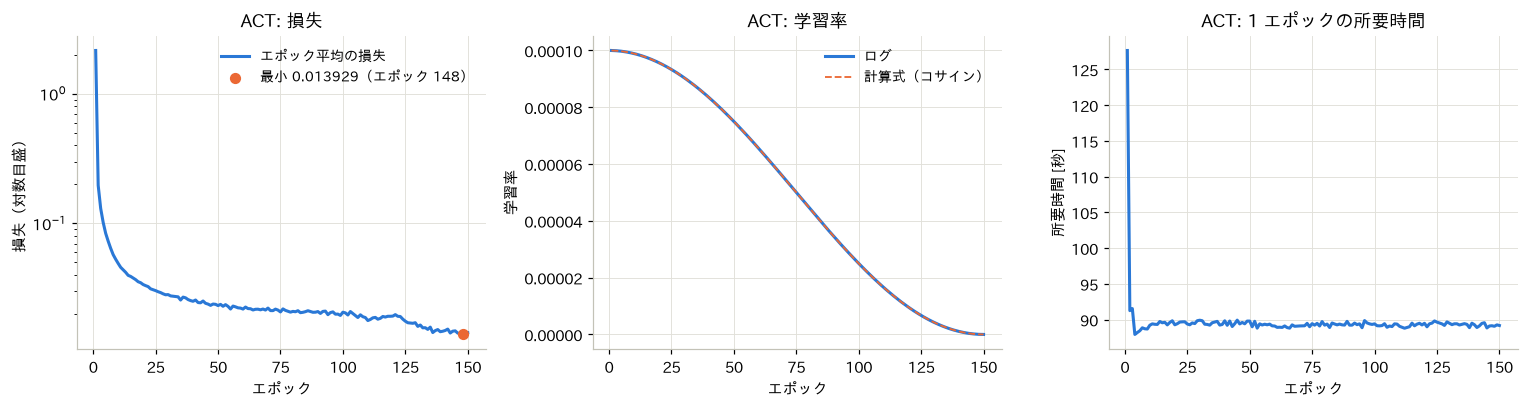

,エポック,損失,1 エポック目に対する比
0,1,2.156914,1.0000
1,2,0.196831,0.0913
2,5,0.083928,0.0389
3,10,0.049198,0.0228
4,20,0.033790,0.0157
5,50,0.023261,0.0108
6,100,0.020671,0.0096
7,140,0.014744,0.0068
8,150,0.014361,0.0067


In [15]:
error = np.abs(act_log["lr"] - expected_lr(act_log["epoch"])).max()
print(f"ACT: ログの学習率（本体）と計算式の差の最大値 = {error:.1e}")
plot_training_curves(act_log, "ACT", "05_act_training_curves.png")
loss_summary(act_log)

### 4.2 学習済みモデルによる予測の確認

ACTの入力の正規化は、学習時に使ったlerobotの前処理器でそのまま行う。
前処理器は保存時の設定でGPUを使うようになっているため、CPUを使うように指定し直す。
出力は標準化された値なので、後処理器に保存された平均・標準偏差で関節角[rad]に戻す。

In [18]:
from lerobot.policies.act.modeling_act import ACTPolicy
from lerobot.processor import PolicyProcessorPipeline
from safetensors.torch import load_file

act_policy = ACTPolicy.from_pretrained(str(ACT_DIR / "best"))
act_policy.to("cpu").eval()
print(f"パラメータ数: {sum(p.numel() for p in act_policy.parameters()):,}")
preprocessor = PolicyProcessorPipeline.from_pretrained(
    str(ACT_DIR / "best"), config_filename="policy_preprocessor.json",
    overrides={"device_processor": {"device": "cpu"}})
# 後処理器（標準化された出力を関節角に戻す処理）に保存された統計
UNNORMALIZER = "policy_postprocessor_step_0_unnormalizer_processor.safetensors"
act_stats = load_file(str(ACT_DIR / "best" / UNNORMALIZER))
print(f"正規化統計のフレーム数: {int(act_stats['action.count'][0]):,}")

act_dataset = LeRobotDataset(
    repo_id="local/so101", root=DATASET_ACT, video_backend="pyav",
    delta_timestamps={"action": [k / FPS for k in range(0, 16)]})
print(f"データセット: {act_dataset.num_episodes}エピソード, {len(act_dataset):,}サンプル")

Loading weights from local directory
パラメータ数: 51,554,182
正規化統計のフレーム数: 69,557
データセット: 457 エピソード, 69,555 サンプル


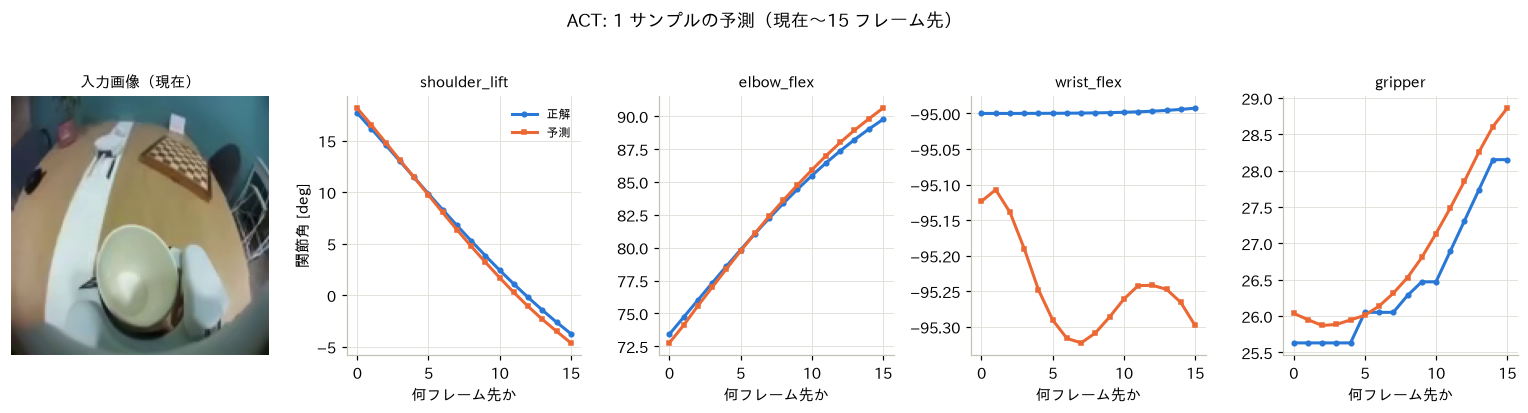

,先の 8 フレームの平均誤差 [deg],先の 16 フレームの平均誤差 [deg]
shoulder_pan,0.27,0.27
shoulder_lift,0.46,0.68
elbow_flex,0.30,0.36
wrist_flex,0.35,0.47
wrist_roll,0.00,0.00
gripper,0.64,0.71


In [19]:
rng = np.random.default_rng(0)
sample_ids = rng.choice(len(act_dataset), size=32, replace=False)
act_samples = [act_dataset[int(i)] for i in sample_ids]
with torch.no_grad():
    batch = preprocessor({
        "observation.state": torch.stack([s["observation.state"]
                                          for s in act_samples]),
        # 学習時の画像入力（observation.image）を、保存後の名前で渡す
        "observation.images.front": torch.stack([s["observation.image"]
                                                 for s in act_samples]),
    })
    predicted = act_policy.predict_action_chunk(batch)     # (B, 16, 6)標準化された値
act_predicted = predicted * act_stats["action.std"] + act_stats["action.mean"]
act_targets = torch.stack([s["action"] for s in act_samples])

plot_prediction(act_samples[0], act_predicted[0], act_targets[0],
                act_samples[0]["observation.image"],
                "ACT: 1サンプルの予測（現在〜15フレーム先）", range(0, 16),
                "05_act_prediction_example.png")
act_errors = error_table(act_predicted, act_targets)
act_errors

学習データから選んだ32サンプルでの誤差は、どの関節も平均1度未満となり、正常な学習が示唆される。

## 5. 実機での実証

キャリブレーションの済んだSO-101をlinuxにつなぎ、下記コマンドにて実行。初期姿勢や対象物の配置を少しずつずらし、想定動作を行えるか確認した。
```bash
lerobot-rollout \
  --strategy.type=base \
  --robot.type=MYROBOTTYPE \
  --robot.port=/dev/ttyACM0 \
  --robot.cameras='{front: {type: opencv, index_or_path: 0, width: 640, height: 480, fps: 30}}' \
  --robot.id=MYROBOTID \
  --robot.max_relative_target=10 \
  --display_data=true \
  --policy.path=/MY/MODEL/PATH
# --policy.resize_shape='[160,160]' # DPのみ映像サイズ変更コマンドを要す
```

別添の動画の通り、DP・ACTいずれもつかみかけるパターンはあったが、最終的につかむ・持ち上げるまで至らなかった。

変換・入力映像・学習のどこに問題があるか探るため、06にてシミュレーション上の検証を行った。